# Simple Model Training
Train a ResNet18 model with concrete configuration and display key metrics

In [1]:
import os, sys
# Ensure project root is in sys.path for src.* imports
PROJECT_ROOT = os.path.abspath(os.path.join(os.path.dirname('__file__'), '..'))
sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)

In [2]:
from src.experiment_notebook import setup_experiment, fine_tune_and_evaluate

In [3]:
# Setup experiment with concrete configuration
ctx = setup_experiment(
    alpha=0.5,
    prev2last_layer_size=256,
    batch_size=32,
    lr=1e-5,
    model_type='patient',        # Activa dropout 0.3
    weight_decay=1e-4,           # L2 regularization
    early_stopping_patience=5,   # Para si val loss no mejora en 5 épocas
)

Device: cpu
Config: alpha=0.5, layer_size=256, batch_size=32, lr=1e-05
Model: PatientFeatureExtractor (dropout=0.3)
Weight decay: 0.0001
Data: 1829 train / 458 test samples
Results dir: ./results_NIH/exp_256_alpha_0.5_20260406_124607


In [4]:
prefixes_to_freeze = ['conv1', 'bn1', 'layer1', 'layer2', 'layer3', 'layer4']
[name for name, _ in ctx['model'].named_parameters() if not any(name.startswith(prefix) for prefix in prefixes_to_freeze)]

['intermediate.0.weight',
 'intermediate.0.bias',
 'classifier.weight',
 'classifier.bias']

In [5]:
# import torch
# 
# # Congelar las primeras capas (conv1 + bn1 + layer1-layer3)
# for name, param in ctx['model'].named_parameters():
#     if any(name.startswith(prefix) for prefix in ['conv1', 'bn1', 'layer1', 'layer2', 'layer3']):
#         param.requires_grad = False
# 
# # Recrear el optimizer solo con los parámetros entrenables
# ctx['optimizer'] = torch.optim.Adam(
#     filter(lambda p: p.requires_grad, ctx['model'].parameters()),
#     lr=1e-4,
#     weight_decay=1e-4
# )

In [6]:
# Train the model for 5 epochs
print("Training model...\n")
results = fine_tune_and_evaluate(ctx, epochs=50, alpha=0.1)

Training model...

  Loss: 0.6151 + 0.1*fairness penalty: 0.0116 # Loss gradient norms: 4.1558 # CE-Loss grad. norms: 4.1809
  Epoch 1, Train Loss: 0.6163, Val Loss: 0.5531
  Loss: 0.4769 + 0.1*fairness penalty: 0.0278 # Loss gradient norms: 4.1525 # CE-Loss grad. norms: 4.1398
  Epoch 2, Train Loss: 0.4796, Val Loss: 0.4666
  Loss: 0.4097 + 0.1*fairness penalty: 0.0185 # Loss gradient norms: 4.6637 # CE-Loss grad. norms: 4.6140
  Epoch 3, Train Loss: 0.4116, Val Loss: 0.4347
  Loss: 0.3631 + 0.1*fairness penalty: 0.0209 # Loss gradient norms: 4.9569 # CE-Loss grad. norms: 4.9030
  Epoch 4, Train Loss: 0.3652, Val Loss: 0.4131
  Loss: 0.3033 + 0.1*fairness penalty: 0.0162 # Loss gradient norms: 5.0426 # CE-Loss grad. norms: 5.0042
  Epoch 5, Train Loss: 0.3049, Val Loss: 0.3990
  Loss: 0.2708 + 0.1*fairness penalty: 0.0183 # Loss gradient norms: 5.1736 # CE-Loss grad. norms: 5.1113
  Epoch 6, Train Loss: 0.2726, Val Loss: 0.4037
  Loss: 0.2167 + 0.1*fairness penalty: 0.0202 # Loss grad

In [7]:
# Display key metrics
print("\n" + "="*60)
print("RESULTADOS - 4 MÉTRICAS CLAVE")
print("="*60)
print(f"1. Global Accuracy:  {results['All']['accuracy']:.4f}")
print(f"2. Global AUC:       {results['All']['auc']:.4f}")
print(f"3. Male Accuracy:    {results['Male']['accuracy']:.4f}")
print(f"4. Female Accuracy:  {results['Female']['accuracy']:.4f}")
print("="*60)


RESULTADOS - 4 MÉTRICAS CLAVE
1. Global Accuracy:  0.8384
2. Global AUC:       0.8944
3. Male Accuracy:    0.8074
4. Female Accuracy:  0.8738


In [8]:
from src.utils.gradcam import collect_gradcam_by_gender, plot_average_heatmaps, plot_sample_heatmaps
import os

# Compute Grad-CAM heatmaps on the test set
gradcam_results = collect_gradcam_by_gender(
    ctx['model'], ctx['test_loader'], ctx['device'], target_class=1
)
print(f"Grad-CAM calculado: {len(gradcam_results['male'])} hombres, {len(gradcam_results['female'])} mujeres")

Grad-CAM calculado: 244 hombres, 214 mujeres


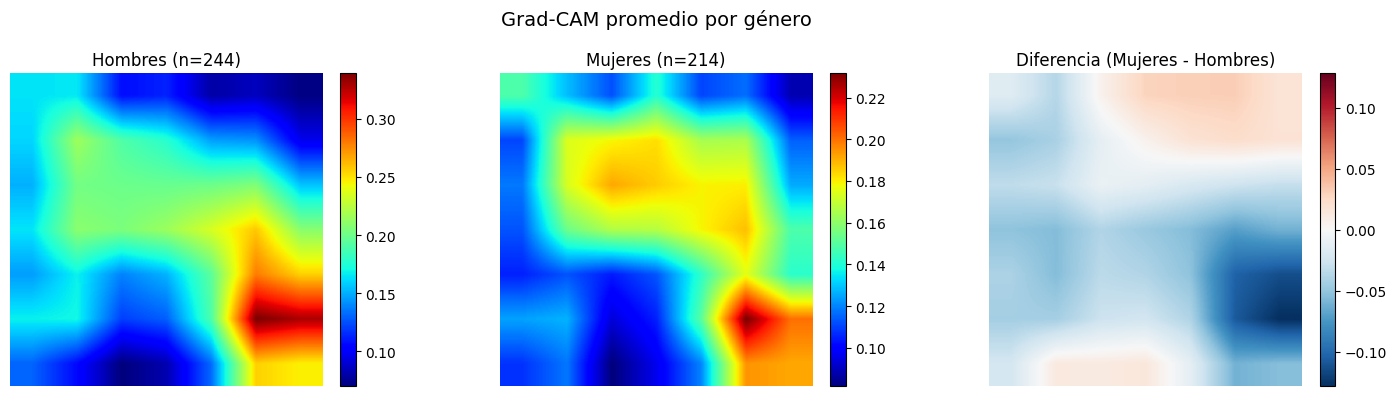

In [9]:
# Average heatmaps: male vs female vs difference
save_dir = ctx['results_dir']
plot_average_heatmaps(gradcam_results, save_path=os.path.join(save_dir, 'gradcam_avg.png'))

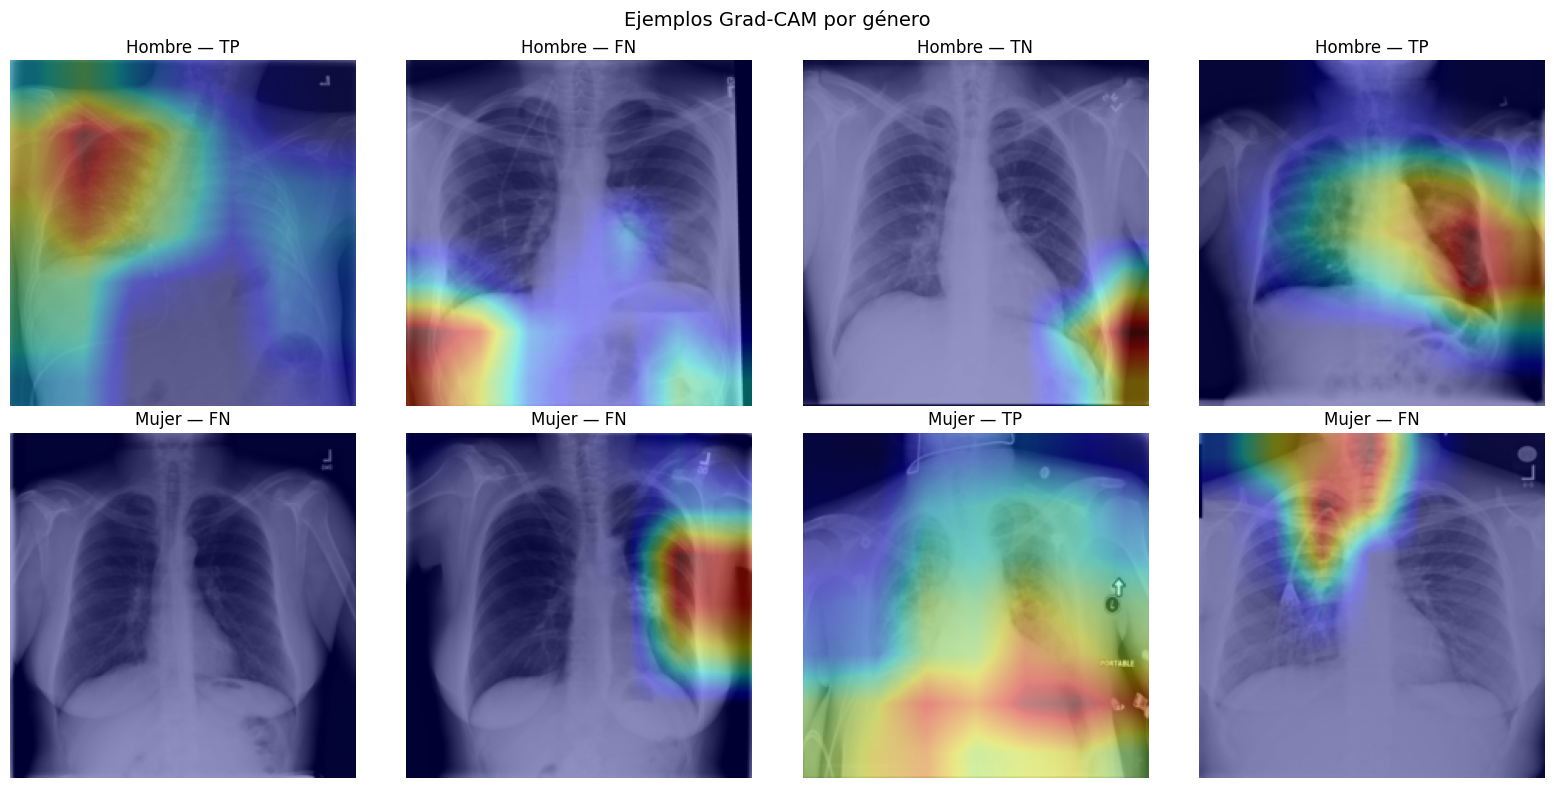

In [10]:
# Individual examples with heatmap overlay
plot_sample_heatmaps(gradcam_results, n_samples=4, save_path=os.path.join(save_dir, 'gradcam_samples.png'))

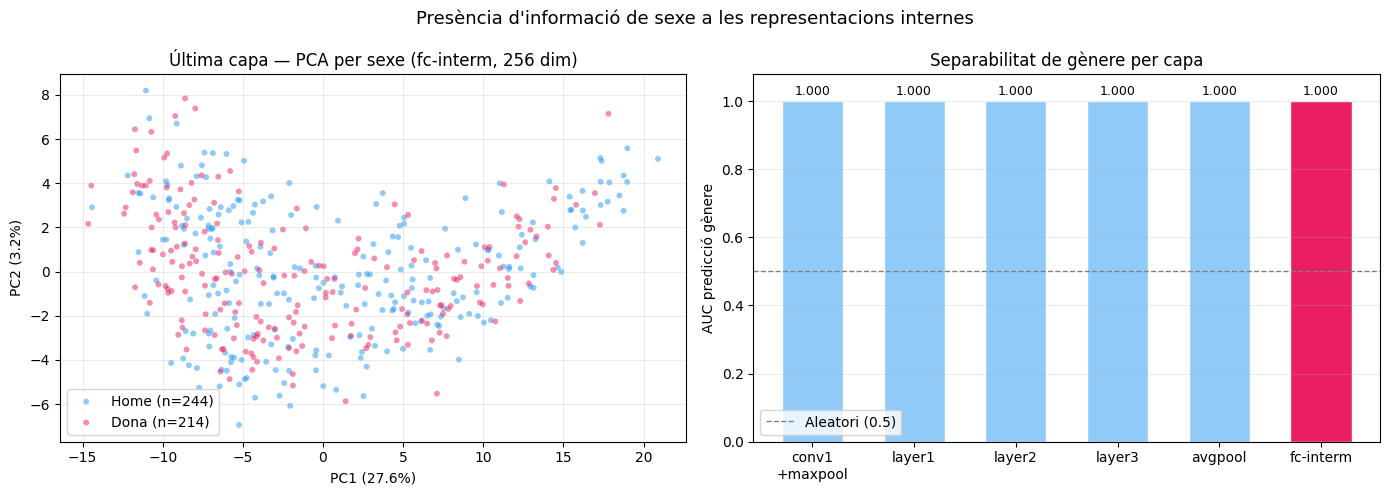

In [11]:
# ── Presència de sexe a l'última capa ──────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Recollir features de l'última capa + gèneres del test set
ctx["model"].eval()
feats_last, genders_vis, labels_vis = [], [], []

with torch.no_grad():
    for images, labels, genders in ctx["test_loader"]:
        images = images.to(ctx["device"])
        ctx["model"](images)
        feats_last.append(ctx["model"].features_all[-1].cpu().numpy())  # capa fc-interm (256-dim)
        genders_vis.extend(genders.numpy())
        labels_vis.extend(labels.numpy())

feats_last  = np.concatenate(feats_last, axis=0)
genders_vis = np.array(genders_vis)
labels_vis  = np.array(labels_vis)

# 2. PCA 2D
pca    = PCA(n_components=2)
feats_2d = pca.fit_transform(StandardScaler().fit_transform(feats_last))

# 3. Figura de dos subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Esquerra: PCA colorejat per sexe ---
colors    = {0: "#2196F3", 1: "#E91E63"}
sex_label = {0: f'Home (n={(genders_vis==0).sum()})', 1: f'Dona (n={(genders_vis==1).sum()})'}
ax = axes[0]
for g in [0, 1]:
    m = genders_vis == g
    ax.scatter(feats_2d[m, 0], feats_2d[m, 1],
               c=colors[g], label=sex_label[g], alpha=0.5, s=18, edgecolors="none")
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title("Última capa — PCA per sexe (fc-interm, 256 dim)")
ax.legend(framealpha=0.8)
ax.grid(alpha=0.25)

# --- Dreta: AUC per capa (de results["gender_pred"]) ---
gender_pred = results.get("gender_pred", {})
n_layers    = len(gender_pred)
layer_ticks = ["conv1\n+maxpool", "layer1", "layer2", "layer3", "avgpool", "fc-interm"][:n_layers]
auc_vals    = [gender_pred[f"layer_{i+1}"]["auc"] for i in range(n_layers)]
bar_colors  = ["#90CAF9"] * (n_layers - 1) + ["#E91E63"]

ax2 = axes[1]
bars = ax2.bar(layer_ticks, auc_vals, color=bar_colors, edgecolor="white", width=0.6)
ax2.axhline(0.5, color="grey", linestyle="--", linewidth=1, label="Aleatori (0.5)")
ax2.set_ylim(0.0, 1.08)
ax2.set_ylabel("AUC predicció gènere")
ax2.set_title("Separabilitat de gènere per capa")
ax2.legend(framealpha=0.8)
ax2.grid(axis="y", alpha=0.25)
for bar, val in zip(bars, auc_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f"{val:.3f}", ha="center", va="bottom", fontsize=9)

plt.suptitle("Presència d'informació de sexe a les representacions internes", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(ctx["results_dir"], "gender_in_layers.png"), dpi=150, bbox_inches="tight")
plt.show()
